# Text encoders for Stable Diffusion: BERT vs. CLIP through a trained connector (+ LoRA)

**Author:** Mukul Sridar Haladhi

SD v1.5's UNet was trained to read **CLIP** text features. Here we swap in **BERT** and ask how much that costs,
and whether fine-tuning the UNet with LoRA helps it adapt.

A fair comparison needs both text encoders to go through the **same** trainable connector, trained the **same** way.
Otherwise we'd be comparing "CLIP with no connector" against "BERT with a freshly trained one".

| Run | Text encoder (frozen) | Trained | Question it answers |
|---|---|---|---|
| `base` | CLIP, direct | nothing | reference |
| `clip_conn` | CLIP | connector | what does adding a from-scratch connector cost? (**control**) |
| `bert_conn` | BERT | connector | BERT vs CLIP, same connector |
| `clip_conn_lora` | CLIP | connector + UNet LoRA | does LoRA help absorb the connector? |
| `bert_conn_lora` | BERT | connector + UNet LoRA | does LoRA help the UNet adapt to BERT? |

Reference from the earlier pilot (same data, prompts, seeds and metric): CLIP direct + LoRA = **26.37** CLIPScore vs base **25.52**.

**Connector:** LayerNorm → Linear(768→1024) → GELU → Linear(1024→768) → LayerNorm, randomly initialised, ~1.58 M params
(about the size of the rank-8 LoRA, 1.59 M). The final LayerNorm matches CLIP, whose last hidden state is itself a LayerNorm output.
BERT-base and CLIP ViT-L/14 both produce 768-d token states, so the connector shape is identical for both.

Everything else (data, steps, batch, optimiser, evaluation) is the same as the LoRA pilot.
Results are copied to Google Drive **after every run**, so a Colab disconnect only loses the run in progress.
Expected time on a T4: ~1.5 h.

## 1. Environment & config

In [1]:
import os, re, json, math, time, random, zipfile, textwrap, unicodedata, urllib.request, shutil, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4 or better)."
DEVICE = "cuda"
print(torch.__version__, torch.cuda.get_device_name(0))

CFG = dict(
    seed=42,
    # data: identical to the LoRA pilot -> identical train set, eval prompts and showcase prompts
    n_train=3000, n_val_loss=100, n_eval_prompts=40, n_showcase=5,
    resolution=512, min_side=384, max_aspect=2.0, min_words=5, max_words=40,
    # models
    sd_model="stable-diffusion-v1-5/stable-diffusion-v1-5",
    bert_model="google-bert/bert-base-uncased",
    clip_model="openai/clip-vit-large-patch14",
    # connector + LoRA
    conn_hidden=1024,
    lora_rank=8, lora_alpha=8, lora_targets=["to_q", "to_k", "to_v", "to_out.0"],
    # optimisation (same budget for every run)
    max_steps=600, batch_size=2, grad_accum=2,
    lr_lora=1e-4, lr_conn=5e-4, lr_warmup=50, weight_decay=1e-2, max_grad_norm=1.0,
    caption_dropout=0.10, gradient_checkpointing=True, val_every=200,
    # sampling
    sample_steps=25, guidance=7.5,
)
RUNS = [  # (name, encoder, use_lora)
    ("clip_conn",      "clip", False),
    ("bert_conn",      "bert", False),
    ("clip_conn_lora", "clip", True),
    ("bert_conn_lora", "bert", True),
]

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["seed"])

ROOT = Path("/content/ft_data") if Path("/content").exists() else Path("./ft_data").resolve()
RAW, IMG_TR, IMG_VA = ROOT/"raw", ROOT/"train_images", ROOT/"val_images"
EXP = ROOT/"runs"/"connector_experiment"
for d in (RAW, IMG_TR, IMG_VA, EXP):
    d.mkdir(parents=True, exist_ok=True)
json.dump({"cfg": CFG, "runs": RUNS}, open(EXP/"config.json", "w"), indent=2)

# Mount Drive now so every finished run is backed up immediately
DRIVE_DIR = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/generative_project/connector_experiment")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
except Exception as e:
    print("Drive not mounted, results stay local:", e)

def backup():
    if DRIVE_DIR is not None:
        shutil.copytree(EXP, DRIVE_DIR, dirs_exist_ok=True)

2.11.0+cu130 Tesla T4
Drive not mounted, results stay local: Mounting drive is unsupported in this environment. Use PyDrive2 instead. See examples at https://colab.research.google.com/notebooks/io.ipynb#scrollTo=7taylj9wpsA2.


## 2. Data (same selection and seed as the LoRA pilot)

In [2]:
ANN_ZIP = RAW/"annotations_trainval2017.zip"
if not (RAW/"annotations"/"captions_train2017.json").exists():
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ANN_ZIP)
    with zipfile.ZipFile(ANN_ZIP) as z:
        for m in ("annotations/captions_train2017.json", "annotations/captions_val2017.json"):
            z.extract(m, RAW)
    ANN_ZIP.unlink()

def load_split(name):
    d = json.load(open(RAW/"annotations"/f"captions_{name}.json"))
    ims = pd.DataFrame(d["images"])[["id", "file_name", "coco_url", "height", "width"]].rename(columns={"id": "image_id"})
    caps = pd.DataFrame(d["annotations"])[["image_id", "caption"]]
    return ims, caps

def clean_caption(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"\s+([.,!?;:])", r"\1", t)
    t = re.sub(r"\b(\w+) \1\b", r"\1", t, flags=re.I)       # "a a dog" -> "a dog"
    return t.rstrip(" .").strip()

def prepare(ims, caps):
    caps = caps.copy()
    caps["clean"] = caps.caption.map(clean_caption)
    n = caps.clean.str.split().str.len()
    caps = caps[n.between(CFG["min_words"], CFG["max_words"])].drop_duplicates(["image_id", "clean"])
    grouped = caps.groupby("image_id").clean.apply(list)
    ims = ims.assign(min_side=ims[["height", "width"]].min(1),
                     aspect=ims[["height", "width"]].max(1) / ims[["height", "width"]].min(1))
    ims = ims[(ims.min_side >= CFG["min_side"]) & (ims.aspect <= CFG["max_aspect"])]
    ims = ims[ims.image_id.isin(grouped.index)].copy()
    ims["captions"] = ims.image_id.map(grouped)
    return ims[ims.captions.str.len() >= 3].reset_index(drop=True)

tr_ims, tr_caps = load_split("train2017")
va_ims, va_caps = load_split("val2017")
tr_pool, va_pool = prepare(tr_ims, tr_caps), prepare(va_ims, va_caps)
print(f"eligible train images: {len(tr_pool):,} | eligible val images: {len(va_pool):,}")

train_df = tr_pool.sample(int(CFG["n_train"] * 1.05), random_state=CFG["seed"]).reset_index(drop=True)  # 5% spare for failed downloads
va_shuf  = va_pool.sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
k1, k2 = CFG["n_val_loss"], CFG["n_val_loss"] + CFG["n_showcase"]
valloss_df   = va_shuf.iloc[:k1].reset_index(drop=True)
showcase_df  = va_shuf.iloc[k1:k2].reset_index(drop=True)
evalprom_df  = va_shuf.iloc[k2:k2 + CFG["n_eval_prompts"]].reset_index(drop=True)

eligible train images: 97,799 | eligible val images: 4,072


In [3]:
def fetch(row, folder):
    dst = folder/row.file_name
    if dst.exists() and dst.stat().st_size > 0:
        return True
    for attempt in range(3):
        try:
            r = requests.get(row.coco_url, timeout=30); r.raise_for_status()
            dst.write_bytes(r.content); return True
        except Exception:
            time.sleep(1 + attempt)
    return False

def fetch_all(df, folder, desc):
    with ThreadPoolExecutor(16) as ex:
        ok = list(tqdm(ex.map(lambda r: fetch(r, folder), df.itertuples()), total=len(df), desc=desc))
    df = df[ok].reset_index(drop=True)
    df["path"] = [str(folder/f) for f in df.file_name]
    return df

train_df    = fetch_all(train_df, IMG_TR, "train images").iloc[:CFG["n_train"]].reset_index(drop=True)
valloss_df  = fetch_all(valloss_df, IMG_VA, "val images")
showcase_df = fetch_all(showcase_df, IMG_VA, "showcase images")
print(f"train pairs: {len(train_df)} images / {train_df.captions.str.len().sum():,} captions | "
      f"val-loss images: {len(valloss_df)} | showcase: {len(showcase_df)} | eval prompts: {len(evalprom_df)}")

train images:   0%|          | 0/3150 [00:00<?, ?it/s]

val images:   0%|          | 0/100 [00:00<?, ?it/s]

showcase images:   0%|          | 0/5 [00:00<?, ?it/s]

train pairs: 3000 images / 15,004 captions | val-loss images: 100 | showcase: 5 | eval prompts: 40


In [4]:
from diffusers import AutoencoderKL
vae = AutoencoderKL.from_pretrained(CFG["sd_model"], subfolder="vae", torch_dtype=torch.float16).to(DEVICE).eval()
SCALE = vae.config.scaling_factor            # 0.18215 for SD v1.5

def load_square(path, size=CFG["resolution"]):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        w, h = im.size; s = size / min(w, h)
        im = im.resize((max(size, round(w*s)), max(size, round(h*s))), Image.Resampling.LANCZOS)
        w, h = im.size; l, t = (w - size)//2, (h - size)//2
        return im.crop((l, t, l + size, t + size))

def to_tensor(im):
    x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 127.5 - 1.0)
    return x.permute(2, 0, 1)

@torch.no_grad()
def cache_latents(df, flips=True, bs=16, desc="latents"):
    lat, lat_f, keep = [], [], []
    for i in tqdm(range(0, len(df), bs), desc=desc):
        xs, ok = [], []
        for j, p in enumerate(df.path.iloc[i:i+bs]):
            try:
                xs.append(to_tensor(load_square(p))); ok.append(i + j)
            except Exception:
                pass
        if not xs: continue
        x = torch.stack(xs).to(DEVICE, torch.float16)
        lat.append((vae.encode(x).latent_dist.sample() * SCALE).cpu())
        if flips:
            lat_f.append((vae.encode(torch.flip(x, dims=[3])).latent_dist.sample() * SCALE).cpu())
        keep += ok
    out = {"lat": torch.cat(lat)}
    if flips: out["lat_flip"] = torch.cat(lat_f)
    return out, df.iloc[keep].reset_index(drop=True)

TRAIN_LAT, train_df = cache_latents(train_df, desc="train latents")
VAL_LAT, valloss_df = cache_latents(valloss_df, flips=False, desc="val latents")
torch.save({"train": TRAIN_LAT, "val": VAL_LAT}, ROOT/"latents.pt")
print("train latents:", tuple(TRAIN_LAT["lat"].shape), "| val latents:", tuple(VAL_LAT["lat"].shape))

del vae; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

train latents:   0%|          | 0/188 [00:00<?, ?it/s]

val latents:   0%|          | 0/7 [00:00<?, ?it/s]

train latents: (3000, 4, 64, 64) | val latents: (100, 4, 64, 64)


## 3. Frozen text encoders and the connector
Both encoders return a `[B, 77, 768]` sequence of token states (padded / truncated to 77 tokens, no attention mask,
exactly as SD v1.5 feeds CLIP). The connector maps that sequence into the UNet's cross-attention input.

In [5]:
from transformers import CLIPTokenizer, CLIPTextModel, BertTokenizerFast, BertModel

clip_tok = CLIPTokenizer.from_pretrained(CFG["sd_model"], subfolder="tokenizer")
clip_enc = CLIPTextModel.from_pretrained(CFG["sd_model"], subfolder="text_encoder", torch_dtype=torch.float16).to(DEVICE).eval()
bert_tok = BertTokenizerFast.from_pretrained(CFG["bert_model"])
bert_enc = BertModel.from_pretrained(CFG["bert_model"], torch_dtype=torch.float16).to(DEVICE).eval()
for m in (clip_enc, bert_enc): m.requires_grad_(False)

@torch.no_grad()
def encode(texts, which):
    if which == "clip":
        ids = clip_tok(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        return clip_enc(ids)[0]
    tk = bert_tok(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(DEVICE)
    return bert_enc(input_ids=tk.input_ids, attention_mask=tk.attention_mask).last_hidden_state

class Connector(nn.Module):
    def __init__(self, d_in=768, d_hidden=CFG["conn_hidden"], d_out=768):
        super().__init__()
        self.ln_in = nn.LayerNorm(d_in)
        self.mlp = nn.Sequential(nn.Linear(d_in, d_hidden), nn.GELU(), nn.Linear(d_hidden, d_out))
        self.ln_out = nn.LayerNorm(d_out)
    def forward(self, x):
        return self.ln_out(self.mlp(self.ln_in(x.float())))

with torch.no_grad():
    c, b = encode(["a dog chasing a cat"], "clip"), encode(["a dog chasing a cat"], "bert")
print("CLIP states", tuple(c.shape), f"std {c.float().std():.3f} | BERT states", tuple(b.shape), f"std {b.float().std():.3f}")
print("connector params:", sum(p.numel() for p in Connector().parameters()) / 1e6, "M")

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (7 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP states (1, 77, 768) std 1.023 | BERT states (1, 77, 768) std 0.412
connector params: 1.577728 M


## 4. Shared pieces: UNet setup, validation loss, generation, CLIPScore
A fresh SD v1.5 UNet is loaded for every run, so no run inherits another's training.

In [6]:
from diffusers import UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline, DPMSolverMultistepScheduler
from diffusers.training_utils import cast_training_params
from diffusers.optimization import get_scheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from transformers import CLIPModel, CLIPProcessor

noise_sched = DDPMScheduler.from_pretrained(CFG["sd_model"], subfolder="scheduler")
T = noise_sched.config.num_train_timesteps

def fresh_unet(use_lora):
    unet = UNet2DConditionModel.from_pretrained(CFG["sd_model"], subfolder="unet", torch_dtype=torch.float16).to(DEVICE)
    unet.requires_grad_(False)
    if use_lora:
        unet.add_adapter(LoraConfig(r=CFG["lora_rank"], lora_alpha=CFG["lora_alpha"],
                                    init_lora_weights="gaussian", target_modules=CFG["lora_targets"]))
        cast_training_params(unet, dtype=torch.float32)
    if CFG["gradient_checkpointing"]:
        unet.enable_gradient_checkpointing()
    return unet

# fixed validation set (same construction as the pilot)
g = torch.Generator().manual_seed(1234)
V_lat   = VAL_LAT["lat"].repeat(2, 1, 1, 1)
V_noise = torch.randn(V_lat.shape, generator=g)
V_t     = torch.linspace(20, T - 20, len(V_lat)).long()[torch.randperm(len(V_lat), generator=g)]
V_caps  = [c[0] for c in valloss_df.captions] * 2

@torch.no_grad()
def validation_loss(unet, embed_fn, bs=8):
    was_training = unet.training; unet.eval(); tot, n = 0.0, 0
    for i in range(0, len(V_lat), bs):
        lat, noise, t = V_lat[i:i+bs].to(DEVICE), V_noise[i:i+bs].to(DEVICE), V_t[i:i+bs].to(DEVICE)
        noisy = noise_sched.add_noise(lat.float(), noise, t).half()
        with torch.autocast("cuda", dtype=torch.float16):
            pred = unet(noisy, t, encoder_hidden_states=embed_fn(V_caps[i:i+bs])).sample
        tot += F.mse_loss(pred.float(), noise, reduction="sum").item(); n += noise.numel()
    unet.train(was_training)
    return tot / n

# one pipeline for VAE / scheduler / safety checker; each run plugs in its own UNet and prompt embeddings
base_pipe = StableDiffusionPipeline.from_pretrained(CFG["sd_model"], torch_dtype=torch.float16).to(DEVICE)
base_pipe.scheduler = DPMSolverMultistepScheduler.from_config(base_pipe.scheduler.config)
base_pipe.set_progress_bar_config(disable=True)

@torch.no_grad()
def generate(unet, embed_fn, prompts, seed0=0, bs=4):
    pipe = StableDiffusionPipeline(**{**base_pipe.components, "unet": unet})
    pipe.set_progress_bar_config(disable=True)
    neg = embed_fn([""]).half()
    imgs, flagged = [], []
    for i in range(0, len(prompts), bs):
        chunk = prompts[i:i+bs]
        gens = [torch.Generator("cpu").manual_seed(seed0 + i + k) for k in range(len(chunk))]
        with torch.autocast("cuda", dtype=torch.float16):
            out = pipe(prompt_embeds=embed_fn(chunk).half(), negative_prompt_embeds=neg.expand(len(chunk), -1, -1),
                       num_inference_steps=CFG["sample_steps"], guidance_scale=CFG["guidance"], generator=gens)
        imgs += out.images
        flagged += list(out.nsfw_content_detected) if out.nsfw_content_detected is not None else [False] * len(chunk)
    return imgs, np.array(flagged)

clip = CLIPModel.from_pretrained(CFG["clip_model"], torch_dtype=torch.float16).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG["clip_model"])

@torch.no_grad()
def clipscore(images, texts):
    x  = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE, torch.float16)
    tk = clip_proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    i = clip.visual_projection(clip.vision_model(pixel_values=x).pooler_output)
    t = clip.text_projection(clip.text_model(input_ids=tk["input_ids"], attention_mask=tk["attention_mask"]).pooler_output)
    i, t = F.normalize(i.float(), dim=-1), F.normalize(t.float(), dim=-1)
    return (100 * (i * t).sum(-1).clamp(min=0)).cpu().numpy()

EVAL_PROMPTS = [c[0] for c in evalprom_df.captions]
SHOW_PROMPTS = [c[0] for c in showcase_df.captions]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (8 outputs left out)

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 5. Reference: the untouched base model (CLIP fed directly, no connector)

In [7]:
base_embed = lambda texts: encode(texts, "clip")
base_unet = base_pipe.unet
RESULTS = {}
imgs, fl = generate(base_unet, base_embed, EVAL_PROMPTS, seed0=0)
show, _  = generate(base_unet, base_embed, SHOW_PROMPTS, seed0=10_000)
RESULTS["base"] = {"scores": clipscore(imgs, EVAL_PROMPTS), "flags": fl, "show": show,
                   "val_loss": validation_loss(base_unet, base_embed), "trainable_params": 0}
(EXP/"base").mkdir(exist_ok=True)
for k, im in enumerate(show): im.save(EXP/"base"/f"showcase_{k+1}.png")
print(f"base: CLIPScore {RESULTS['base']['scores'].mean():.2f} | val loss {RESULTS['base']['val_loss']:.5f}")

base: CLIPScore 25.50 | val loss 0.15120


## 6. Train every run
Same objective as the pilot (ε-prediction MSE, 10% caption dropout, AdamW + warmup/cosine, fp16 autocast + GradScaler).
The connector starts from random weights, so it gets a higher learning rate (5e-4) than the LoRA adapters (1e-4).

In [9]:
import peft.import_utils as _iu
import peft.tuners.lora.torchao as _lt
_iu.is_torchao_available = lambda: False
_lt.is_torchao_available = lambda: False
print("torchao check disabled")

torchao check disabled


In [10]:
def train_run(name, which, use_lora):
    seed_everything(CFG["seed"])
    out_dir = EXP/name; (out_dir/"samples").mkdir(parents=True, exist_ok=True)
    unet = fresh_unet(use_lora)
    conn = Connector().to(DEVICE)
    embed_fn = lambda texts: conn(encode(texts, which))

    groups = [{"params": list(conn.parameters()), "lr": CFG["lr_conn"]}]
    lora_params = [p for p in unet.parameters() if p.requires_grad]
    if lora_params: groups.append({"params": lora_params, "lr": CFG["lr_lora"]})
    all_params = [p for grp in groups for p in grp["params"]]
    n_conn, n_lora = sum(p.numel() for p in conn.parameters()), sum(p.numel() for p in lora_params)

    opt = torch.optim.AdamW(groups, weight_decay=CFG["weight_decay"])
    sched = get_scheduler("cosine", opt, num_warmup_steps=CFG["lr_warmup"], num_training_steps=CFG["max_steps"])
    scaler = torch.amp.GradScaler("cuda")
    N, B, caps_all = len(train_df), CFG["batch_size"], train_df.captions.tolist()

    val_log = [{"step": 0, "val_loss": validation_loss(unet, embed_fn)}]
    log = []
    unet.train(); conn.train()
    torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for step in tqdm(range(1, CFG["max_steps"] + 1), desc=name):
        step_loss = 0.0
        for _ in range(CFG["grad_accum"]):
            idx  = torch.randint(0, N, (B,))
            flip = torch.rand(B) < 0.5
            lat  = torch.where(flip[:, None, None, None], TRAIN_LAT["lat_flip"][idx], TRAIN_LAT["lat"][idx]).to(DEVICE).float()
            caps = ["" if random.random() < CFG["caption_dropout"] else random.choice(caps_all[i]) for i in idx.tolist()]
            noise = torch.randn_like(lat)
            t = torch.randint(0, T, (B,), device=DEVICE).long()
            noisy = noise_sched.add_noise(lat, noise, t).half()
            with torch.autocast("cuda", dtype=torch.float16):
                pred = unet(noisy, t, encoder_hidden_states=embed_fn(caps)).sample
            loss = F.mse_loss(pred.float(), noise) / CFG["grad_accum"]
            scaler.scale(loss).backward(); step_loss += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(all_params, CFG["max_grad_norm"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        log.append({"step": step, "loss": step_loss})
        if step % CFG["val_every"] == 0 or step == CFG["max_steps"]:
            val_log.append({"step": step, "val_loss": validation_loss(unet, embed_fn)})
            print(f"  step {step}: val loss {val_log[-1]['val_loss']:.5f}")
    train_min, peak = (time.time() - t0) / 60, torch.cuda.max_memory_allocated() / 1e9

    # save weights + logs
    torch.save(conn.state_dict(), out_dir/"connector.pt")
    if use_lora:
        StableDiffusionPipeline.save_lora_weights(save_directory=str(out_dir),
            unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)), safe_serialization=True)
    pd.DataFrame(log).to_csv(out_dir/"train_log.csv", index=False)
    pd.DataFrame(val_log).to_csv(out_dir/"val_log.csv", index=False)

    # evaluate with the same prompts and seeds as the base model
    unet.eval(); conn.eval()
    imgs, fl = generate(unet, embed_fn, EVAL_PROMPTS, seed0=0)
    show, _  = generate(unet, embed_fn, SHOW_PROMPTS, seed0=10_000)
    for k, im in enumerate(show): im.save(out_dir/"samples"/f"showcase_{k+1}.png")
    res = {"scores": clipscore(imgs, EVAL_PROMPTS), "flags": fl, "show": show,
           "val_loss": val_log[-1]["val_loss"], "val_log": val_log,
           "trainable_params": n_conn + n_lora, "connector_params": n_conn, "lora_params": n_lora,
           "train_minutes": round(train_min, 1), "peak_gpu_gb": round(peak, 2)}
    json.dump({k: v for k, v in res.items() if k not in ("scores", "flags", "show")} |
              {"clipscore_mean": float(res["scores"].mean())}, open(out_dir/"summary.json", "w"), indent=2)
    print(f"{name}: CLIPScore {res['scores'].mean():.2f} | val loss {res['val_loss']:.5f} | {train_min:.1f} min")

    del unet, conn, opt, scaler; gc.collect(); torch.cuda.empty_cache()
    return res

for name, which, use_lora in RUNS:
    if name in RESULTS: continue          # lets you re-run this cell after a crash without redoing finished runs
    RESULTS[name] = train_run(name, which, use_lora)
    backup()

clip_conn_lora:   0%|          | 0/600 [00:00<?, ?it/s]

  step 200: val loss 0.15283
  step 400: val loss 0.15226
  step 600: val loss 0.15197
clip_conn_lora: CLIPScore 13.69 | val loss 0.15197 | 13.4 min


bert_conn_lora:   0%|          | 0/600 [00:00<?, ?it/s]

  step 200: val loss 0.15286
  step 400: val loss 0.15219
  step 600: val loss 0.15202


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


bert_conn_lora: CLIPScore 11.83 | val loss 0.15202 | 13.4 min


## 7. Results
Every comparison is paired: same 40 held-out prompts, same seeds. The interval is a paired bootstrap 95% CI.

In [11]:
def paired_bootstrap(a, b, n=5000, seed=0):
    d = b - a; rng = np.random.default_rng(seed)
    boots = rng.choice(d, (n, len(d)), replace=True).mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

def compare(ref, other):
    keep = ~(RESULTS[ref]["flags"] | RESULTS[other]["flags"])
    a, b = RESULTS[ref]["scores"][keep], RESULTS[other]["scores"][keep]
    m, lo, hi = paired_bootstrap(a, b)
    return f"{m:+.2f} [{lo:+.2f}, {hi:+.2f}]", round(float((b > a).mean()), 2)

info = {n: (w, l) for n, w, l in RUNS}
rows = []
for name, r in RESULTS.items():
    w, l = info.get(name, ("clip", False))
    row = {"run": name, "text encoder": w.upper(),
           "connector": "no" if name == "base" else "yes", "LoRA": "yes" if l else "no",
           "trainable params (M)": round(r["trainable_params"] / 1e6, 2),
           "CLIPScore": round(float(r["scores"].mean()), 2), "val loss": round(r["val_loss"], 5)}
    if name != "base":
        row["Δ vs base [95% CI]"], row["win rate vs base"] = compare("base", name)
    rows.append(row)
TABLE = pd.DataFrame(rows)
TABLE.to_csv(EXP/"results_table.csv", index=False)
display(TABLE)

# the comparisons that answer the questions
pairs = [("clip_conn", "bert_conn", "BERT vs CLIP, connector only"),
         ("clip_conn_lora", "bert_conn_lora", "BERT vs CLIP, connector + LoRA"),
         ("bert_conn", "bert_conn_lora", "does LoRA help BERT?"),
         ("clip_conn", "clip_conn_lora", "does LoRA help CLIP + connector?")]
cmp_rows = []
for a, b, q in pairs:
    if a in RESULTS and b in RESULTS:
        d, wr = compare(a, b)
        cmp_rows.append({"question": q, "comparison": f"{b} − {a}", "Δ CLIPScore [95% CI]": d, "win rate": wr})
COMPARISONS = pd.DataFrame(cmp_rows)
COMPARISONS.to_csv(EXP/"key_comparisons.csv", index=False)
display(COMPARISONS)

,run,text encoder,connector,LoRA,trainable params (M),CLIPScore,val loss,Δ vs base [95% CI],win rate vs base
0,base,CLIP,no,no,0.00,25.50,0.15120,NaN,NaN
1,clip_conn,CLIP,yes,no,1.58,14.35,0.15241,"-11.20 [-13.11, -9.38]",0.03
2,bert_conn,BERT,yes,no,1.58,12.43,0.15238,"-13.07 [-14.71, -11.48]",0.00
3,clip_conn_lora,CLIP,yes,yes,3.17,13.69,0.15197,"-11.81 [-13.65, -10.01]",0.03
4,bert_conn_lora,BERT,yes,yes,3.17,11.83,0.15202,"-13.73 [-15.16, -12.28]",0.00


,question,comparison,Δ CLIPScore [95% CI],win rate
0,"BERT vs CLIP, connector only",bert_conn − clip_conn,"-1.95 [-3.47, -0.50]",0.33
1,"BERT vs CLIP, connector + LoRA",bert_conn_lora − clip_conn_lora,"-2.16 [-3.96, -0.41]",0.44
2,does LoRA help BERT?,bert_conn_lora − bert_conn,"-0.81 [-2.13, +0.49]",0.51
3,does LoRA help CLIP + connector?,clip_conn_lora − clip_conn,"-0.51 [-2.30, +1.35]",0.41


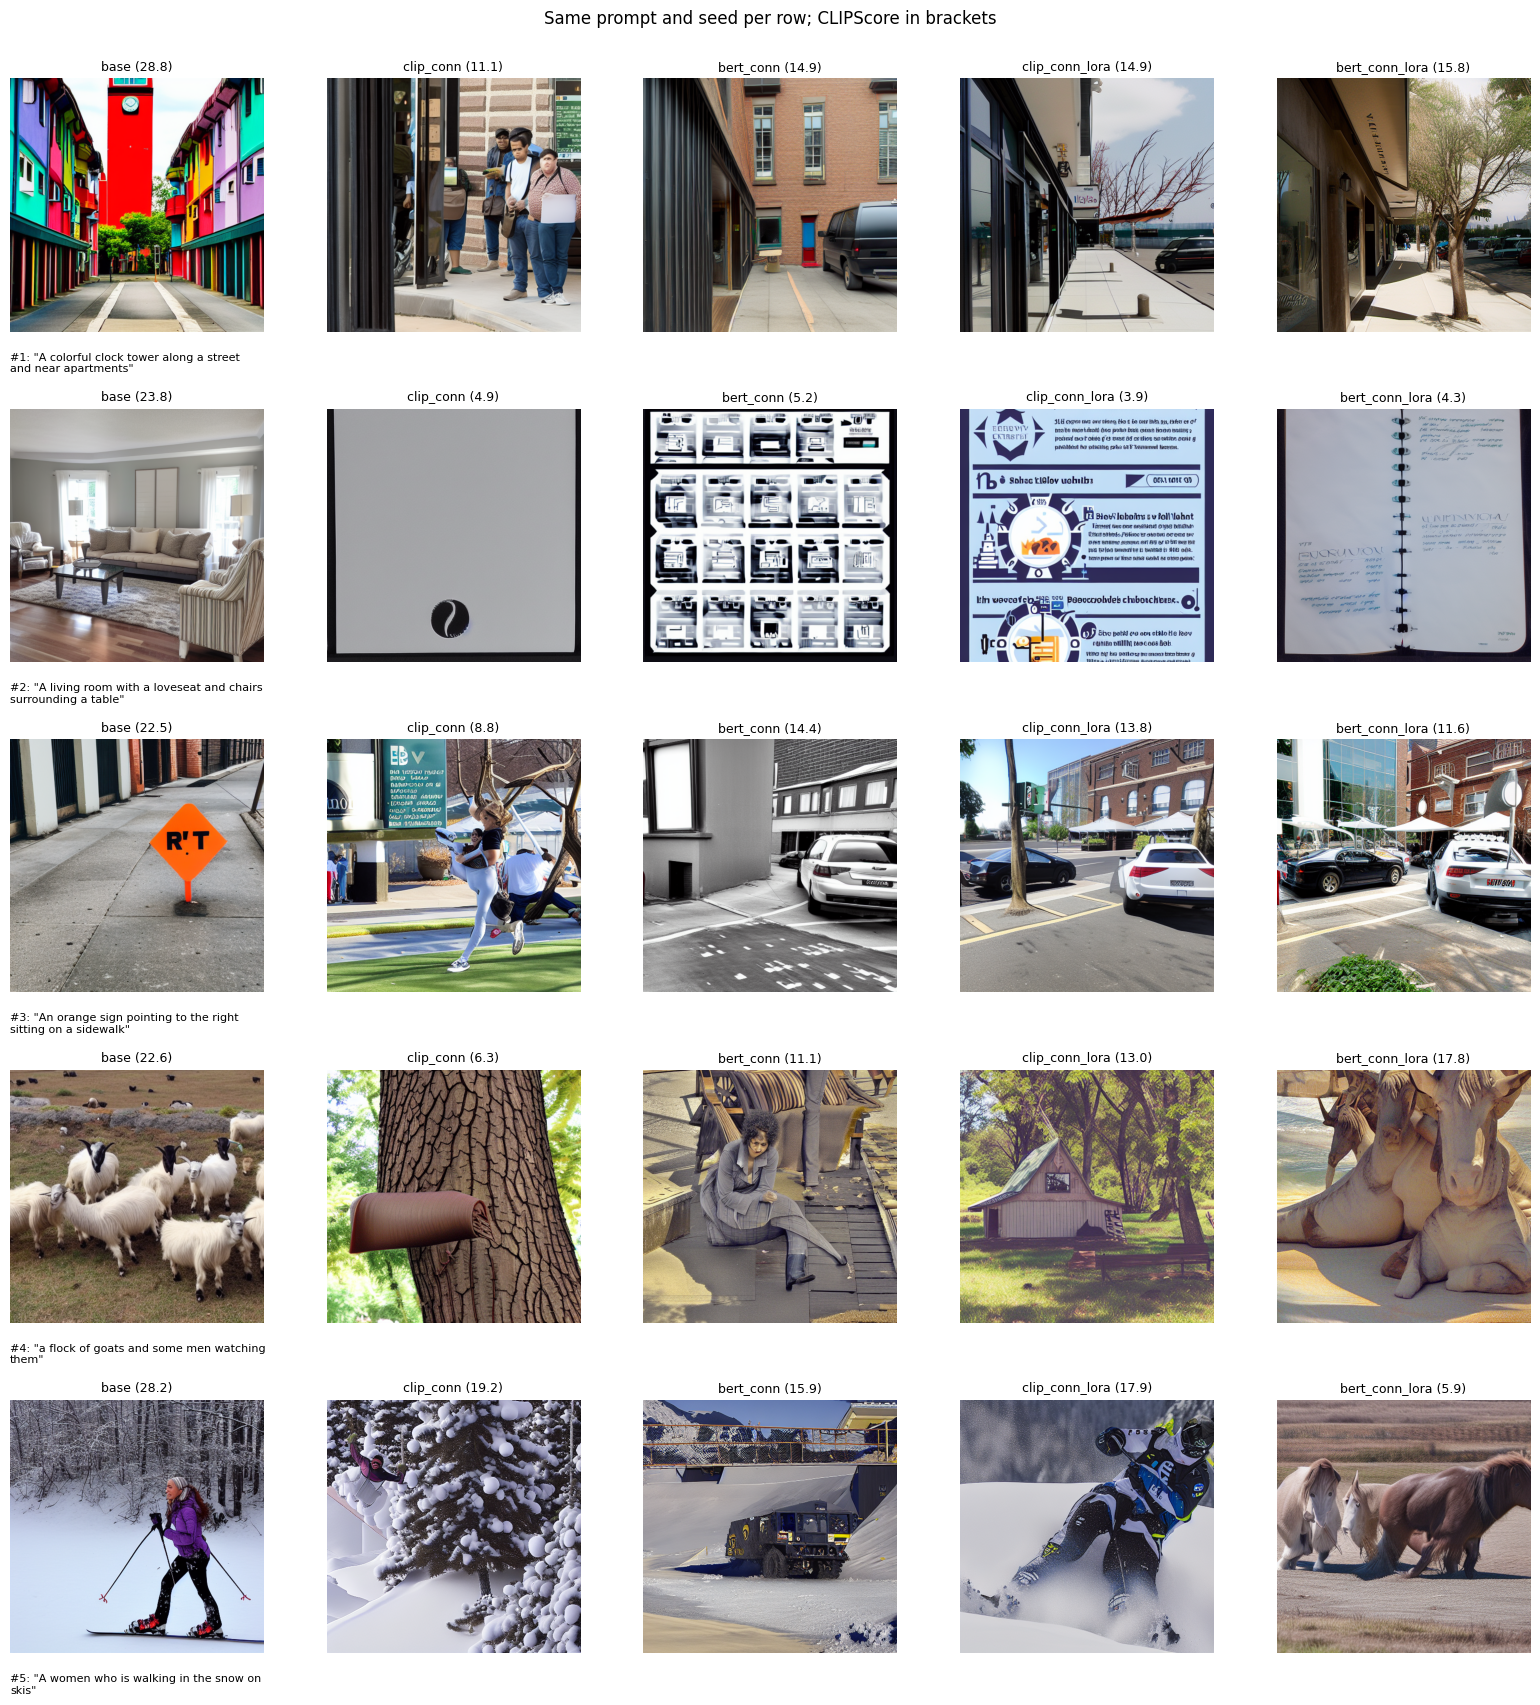

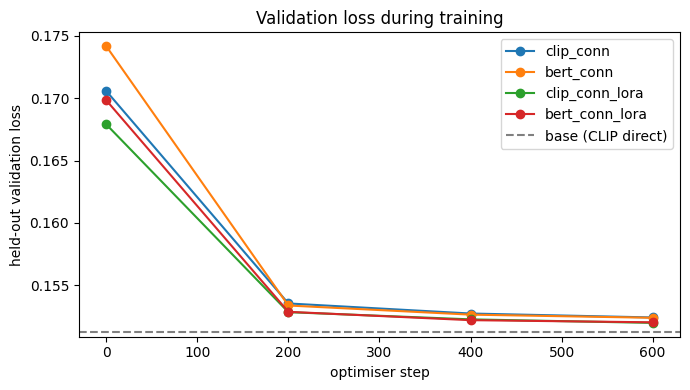

saved to /content/ft_data/runs/connector_experiment 


In [12]:
names = list(RESULTS)
fig, axes = plt.subplots(len(SHOW_PROMPTS), len(names), figsize=(3.1 * len(names), 3.4 * len(SHOW_PROMPTS)))
for k in range(len(SHOW_PROMPTS)):
    cs = {n: clipscore([RESULTS[n]["show"][k]], [SHOW_PROMPTS[k]])[0] for n in names}
    for j, n in enumerate(names):
        a = axes[k, j]; a.imshow(RESULTS[n]["show"][k]); a.axis("off")
        a.set_title(f"{n} ({cs[n]:.1f})", fontsize=9)
    axes[k, 0].text(0, -0.08, "\n".join(textwrap.wrap(f'#{k+1}: "{SHOW_PROMPTS[k]}"', 45)),
                    transform=axes[k, 0].transAxes, fontsize=8, va="top")
plt.suptitle("Same prompt and seed per row; CLIPScore in brackets", y=1.0)
plt.tight_layout(); plt.savefig(EXP/"showcase_grid.png", dpi=130, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for n in names:
    if n == "base": continue
    vl = pd.DataFrame(RESULTS[n]["val_log"]); ax.plot(vl.step, vl.val_loss, "o-", label=n)
ax.axhline(RESULTS["base"]["val_loss"], ls="--", c="gray", label="base (CLIP direct)")
ax.set(xlabel="optimiser step", ylabel="held-out validation loss", title="Validation loss during training"); ax.legend()
plt.tight_layout(); plt.savefig(EXP/"val_loss_curves.png", dpi=150); plt.show()

backup()
print("saved to", EXP, "and Drive" if DRIVE_DIR else "")